# Ejercicio 1

## Contexto

Trabajas en el departamento de sistemas de una empresa que gestiona una tienda online.

Durante los últimos días, varios clientes han comunicado que la web funciona especialmente lenta en determinados momentos. Algunos aseguran que incluso ha dejado de responder durante unos segundos.

El responsable de infraestructura sospecha que el problema podría estar relacionado con el tráfico recibido, aunque desconoce si existe realmente una relación entre el número de peticiones y el tiempo de respuesta del servidor.

Para realizar una primera investigación, te encarga analizar una simulación del comportamiento del servidor durante 24 horas.

## Datos disponibles

Como todavía no se dispone de un sistema de monitorización completo, tendrás que generar un conjunto de datos simulado. Estas son las características que debes tener en cuenta:

- Periodo de observación: 24 horas, de 0 a 23
- Tráfico habitual: Entre 50 y 100 peticiones por minuto
- Tráfico de 18 a 20h: Aumento adicional de 120 a 180 peticiones por minuto
- Tiempo de respuesta (en ms): 50 + peticiones por minuto × 1.8 + variación aleatoria
- Variación aleatoria: Entre 0 y 40 ms
- Tráfico elevado: Más de 12000 peticiones/hora
- Respuesta lenta: Más de 400 ms

## Lo que tienes que hacer

El responsable técnico necesita un informe que le permita determinar si existe algún problema de rendimiento, cuándo aparece y qué posibles causas deberían investigarse. Debes aportarle el fichero csv de la monitorización (generado aleatoriamente con las condiciones dadas), el fichero json con las incidencias registradas y algunas gráficas en jpg que aporten valor a tu decisión.

El código que desarrolles debe responder a:

1. ¿Se comporta el servidor de manera similar durante todo el día o existen periodos claramente diferentes?

2. ¿Existe alguna relación entre el tráfico recibido y la lentitud de la web?

3. ¿En qué momentos debería centrarse inicialmente la investigación del departamento técnico? Identifica los registros relevantes y explica los criterios utilizados para seleccionarlos.

4. ¿Se producen situaciones de respuesta lenta sin que exista tráfico elevado, o situaciones de tráfico elevado sin respuesta lenta?

5. ¿Podemos afirmar que la web ha sufrido una caída?

## Entrega

- Script en python > actividad.py o actividad.ipynb
- Datos de monitorización generados automáticamente > monitorizacion.csv
- Registros relevantes o incidencias registradas > incidencias.json
- Gráficas que consideres necesarias en formato jpg.
- Informe de conclusiones > actividad.md o actividad.ipynb

Cuanto más expliques lo que haces mejor (comenta tu código, da una visión crítica y constructiva, etc.)

## 1. Generación de datos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Semilla fija para repetir la simulación.
np.random.seed(42)
hora = np.arange(24)
ppm = np.random.randint(50, 101, 24)
pico = (hora >= 18) & (hora <= 20)
# El aumento es adicional al tráfico habitual.
ppm[pico] += np.random.randint(120, 181, pico.sum())
df = pd.DataFrame({'hora': hora, 'peticiones_min': ppm,
                   'peticiones_hora': ppm * 60,
                   'respuesta_ms': 50 + ppm * 1.8 + np.random.uniform(0, 40, 24)})
df['trafico_elevado'] = df['peticiones_hora'] > 12000
df['respuesta_lenta'] = df['respuesta_ms'] > 400

print(df.head())
print(df.shape)

   hora  peticiones_min  ...  trafico_elevado  respuesta_lenta
0     0              88  ...            False            False
1     1              78  ...            False            False
2     2              64  ...            False            False
3     3              92  ...            False            False
4     4              57  ...            False            False

[5 rows x 6 columns]
(24, 6)


## 2. Incidencias y exportación

In [ ]:
# Exportamos todos los datos y seleccionamos las incidencias.
df.to_csv('monitorizacion.csv', index=False)
incidencias = df[df['trafico_elevado'] | df['respuesta_lenta']]
incidencias.to_json('incidencias.json', orient='records', indent=4, force_ascii=False)
print(incidencias.to_string(index=False))
print('Total de incidencias:', len(incidencias))
print(pd.crosstab(df['trafico_elevado'], df['respuesta_lenta']))


 hora  peticiones_min  peticiones_hora  respuesta_ms  trafico_elevado  respuesta_lenta
   18             225            13500    487.335894             True             True
   19             224            13440    465.384551             True             True
   20             256            15360    514.706885             True             True
Total de incidencias: 3
respuesta_lenta  False  True 
trafico_elevado              
False               21      0
True                 0      3


## 3. Análisis exploratorio

In [ ]:
print(df.select_dtypes(include='number').corr().round(2))
print(df.groupby(df['hora'].between(18,20))[['peticiones_hora','respuesta_ms']].mean())


                 hora  peticiones_min  peticiones_hora  respuesta_ms
hora             1.00            0.35             0.35          0.35
peticiones_min   0.35            1.00             1.00          0.99
peticiones_hora  0.35            1.00             1.00          0.99
respuesta_ms     0.35            0.99             0.99          1.00
       peticiones_hora  respuesta_ms
hora                                
False      4282.857143    196.115933
True      14100.000000    489.142443


## 4. Gráficas

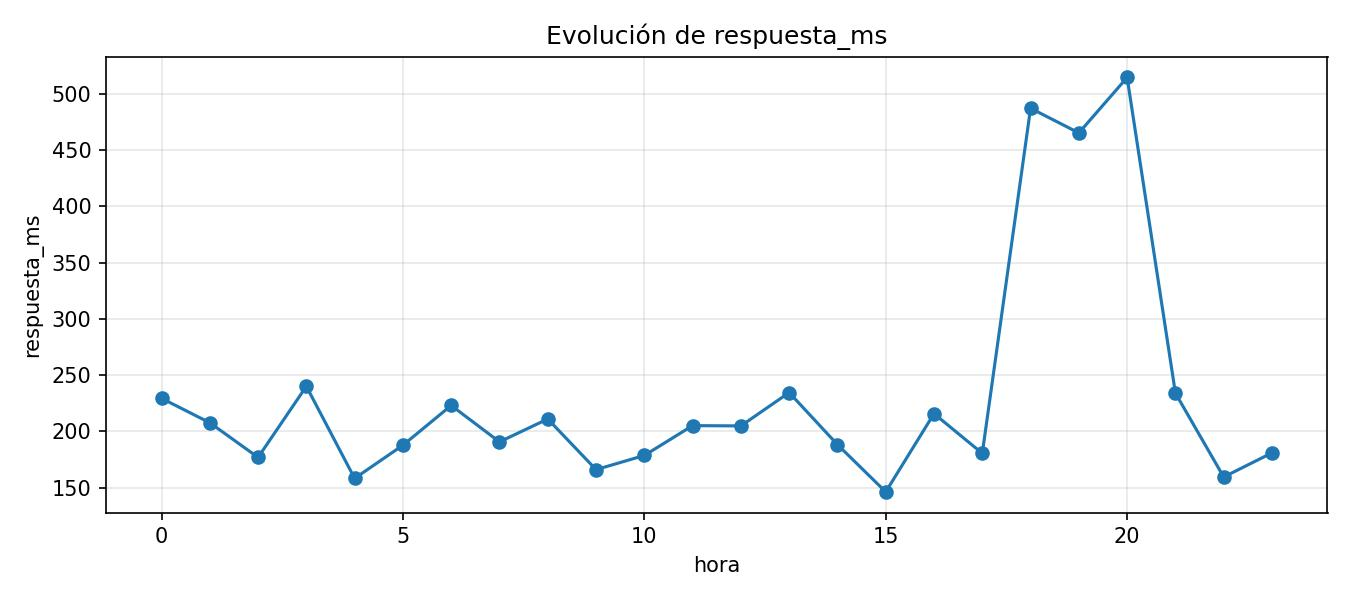

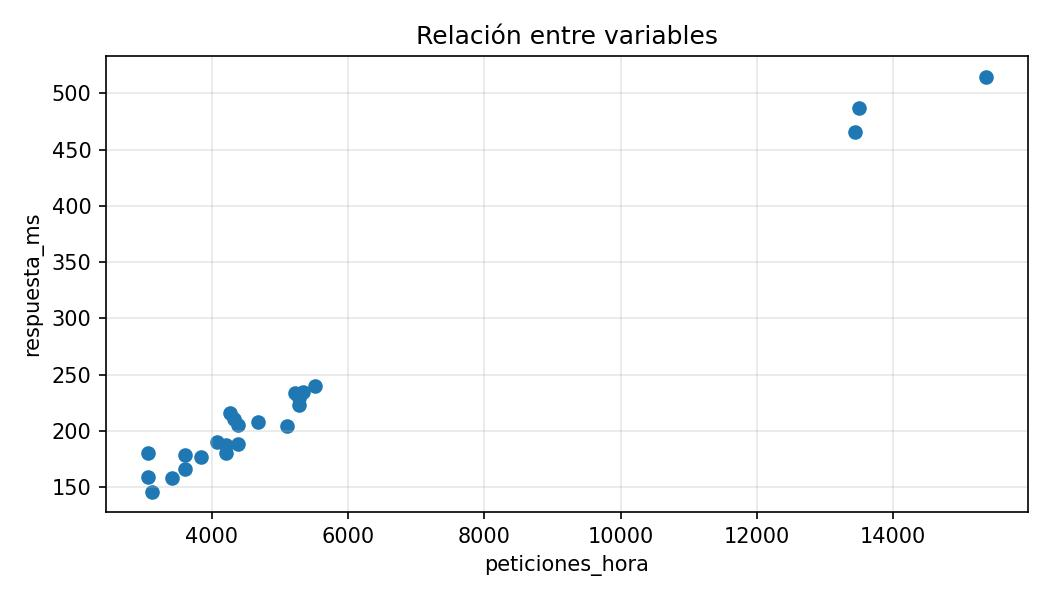

In [ ]:
# Evolución por registro: permite localizar los momentos problemáticos.
plt.figure(figsize=(9, 4))
plt.plot(df['hora'], df['respuesta_ms'], marker='o')
plt.xlabel('hora'); plt.ylabel('respuesta_ms'); plt.title('Evolución de respuesta_ms')
plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig('evolucion.jpg', dpi=150); plt.show()
plt.figure(figsize=(7, 4))
plt.scatter(df['peticiones_hora'], df['respuesta_ms'])
plt.xlabel('peticiones_hora'); plt.ylabel('respuesta_ms'); plt.title('Relación entre variables')
plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig('relacion.jpg', dpi=150); plt.show()


## 5. Conclusiones

1. El periodo 18–20 h tiene un tráfico medio de 14100 peticiones/hora frente a 4283 el resto del día.
2. La correlación tráfico-respuesta es 0.99; la fórmula de simulación incorpora esa relación.
3. Investigar las horas [18, 19, 20], seleccionadas por superar 12000 peticiones/hora o 400 ms. Revisar CPU, memoria y consultas.
4. Ambos criterios: 3; solo tráfico elevado: 0; solo respuesta lenta: 0.
5. No se puede afirmar una caída: faltan códigos HTTP, disponibilidad y errores.

Los datos son simulados y no prueban el comportamiento de un sistema real.